# Airbnb Madrid — Si no es el precio, ¿qué explica la nota?

Continuación de `02_analisis_exploratorio.ipynb`. Allí encontramos algo que dejamos abierto:
el **rating apenas correlaciona con el precio** (r ≈ 0,09). Lo habitual es descartar ese
resultado como «no hay señal» y seguir. Aquí hacemos lo contrario: lo tomamos como punto de
partida.

Si pagar más no compra mejores reseñas, **algo** tiene que explicarlas. Este notebook busca
qué, y el camino acaba en un sitio inesperado: no en el alojamiento, sino en **quién lo
gestiona**.

Estructura: cada sección plantea una pregunta, la responde con datos y decide si seguir
tirando del hilo o cerrarlo.

## 0. Setup

Misma paleta y estilo de gráficos que el notebook 02, para que todo el trabajo sea coherente.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats

# --- paleta (misma que el notebook 02 y el dashboard) ---
INK, INK2, MUTED = '#0b0b0b', '#52514e', '#898781'
GRID, BASE, SURFACE = '#e1e0d9', '#c3c2b7', '#fcfcfb'
BLUE, BLUE_L, BLUE_D = '#2a78d6', '#9ec5f4', '#104281'
RED, AQUA = '#e34948', '#1baf7a'

mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': BASE, 'axes.linewidth': 1,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK2,
    'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titleweight': 'bold',
    'axes.titlesize': 12, 'axes.titlelocation': 'left', 'axes.titlepad': 12,
    'font.size': 10, 'figure.dpi': 110, 'legend.frameon': False,
})

def estilo(ax, eje='y'):
    ax.grid(axis=eje)
    ax.grid(axis='x' if eje == 'y' else 'y', visible=False)
    ax.tick_params(length=0)

In [2]:
full = pd.read_parquet('../data/processed/listings_full.parquet')

# Base de trabajo: anuncios con nota y con precio conocido, sin el 1% superior de precio.
# Exigimos ambas para que TODOS los factores se comparen sobre la misma muestra (si no,
# cada correlación se calcularía sobre un subconjunto distinto y no serían comparables).
b = full[full.price.notna() & (full.price < full.price.quantile(0.99))].copy()
b = b[b.review_scores_rating.notna()]

b['log_price'] = np.log(b['price'])
b['price_pp'] = b['price'] / b['accommodates'].clip(lower=1)
b['log_host'] = np.log(b['calculated_host_listings_count'].clip(lower=1))
b['es_super'] = (b['host_is_superhost'] == 't').astype(float)
b['antiguedad'] = ((pd.Timestamp('2026-06-20') - pd.to_datetime(b['first_review'])).dt.days
                   / 365.25)

print(f'anuncios totales:      {len(full):,}')
print(f'base de este notebook: {len(b):,}  (con nota y con precio, sin el 1% superior)')
print(f'barrios: {b.neighbourhood_cleansed.nunique()}   tipos: {b.room_type.nunique()}')

anuncios totales:      22,708
base de este notebook: 16,360  (con nota y con precio, sin el 1% superior)
barrios: 126   tipos: 4


## 1. El punto de partida: ¿cuánto explica el precio, en realidad?

En el notebook 02 vimos la correlación (r ≈ 0,09) pero no la traducimos a algo interpretable.
La correlación por sí sola engaña: lo que importa para saber si un factor «explica» algo es
**r², la proporción de varianza explicada**.

In [3]:
r, p = stats.pearsonr(b.log_price, b.review_scores_rating)
print(f'log(precio) ~ rating:  r = {r:+.3f}   p = {p:.2g}   n = {len(b):,}')
print(f'varianza del rating explicada por el precio:  r2 = {r**2:.3%}')

log(precio) ~ rating:  r = +0.091   p = 2.2e-31   n = 16,360
varianza del rating explicada por el precio:  r2 = 0.827%


**Lectura:** el precio explica **menos del 1%** de la variación en las notas. Es
estadísticamente significativo (con 16.000 anuncios casi todo lo es) pero **prácticamente
irrelevante**: es el ejemplo de manual de por qué significancia y tamaño de efecto no son lo
mismo.

Antes de descartarlo, una duda razonable: ¿y si ese 0,9% fuera un **artefacto de
composición**? Los pisos caros están en Centro y Salamanca y suelen ser pisos enteros. Quizá
no medimos «caro → mejor nota», sino «mejor barrio → mejor nota».

## 2. Control de confusores: correlación parcial dentro de barrio × tipo

Para separarlo, comparamos sólo alojamientos **del mismo barrio y del mismo tipo**. La forma
directa de hacerlo es restar a cada variable la media de su celda (*demeaning*): lo que queda
es la variación *dentro* de la celda, ya limpia del efecto de barrio y tipo.

In [4]:
def corr_parcial(df, x, y, celdas, min_celda=5):
    '''Correlación de x,y tras absorber las medias de cada celda (efectos fijos).

    Devuelve (r, p, n, nº de celdas). Los grados de libertad se ajustan por las medias
    absorbidas, si no el p-valor saldría optimista.
    '''
    f = df[[x, y] + celdas].dropna()
    f = f[f.groupby(celdas)[x].transform('size') >= min_celda]
    g = f.groupby(celdas)
    xd = f[x] - g[x].transform('mean')
    yd = f[y] - g[y].transform('mean')
    n, k = len(f), g.ngroups
    r = np.corrcoef(xd, yd)[0, 1]
    gl = n - k - 1
    t = r * np.sqrt(gl / (1 - r ** 2))
    return r, 2 * stats.t.sf(abs(t), gl), n, k

CELDAS = ['neighbourhood_cleansed', 'room_type']

r_bruto = stats.pearsonr(b.log_price, b.review_scores_rating)[0]
r_par, p_par, n_par, k_par = corr_parcial(b, 'log_price', 'review_scores_rating', CELDAS)

print(f'bruto                     r = {r_bruto:+.3f}')
print(f'dentro de barrio x tipo   r = {r_par:+.3f}   p = {p_par:.2g}   '
      f'(n = {n_par:,}, {k_par} celdas)')
print(f'                          r2 = {r_par**2:.3%}')

bruto                     r = +0.091
dentro de barrio x tipo   r = +0.096   p = 5.1e-34   (n = 16,245, 230 celdas)
                          r2 = 0.919%


**Hallazgo (y callejón sin salida):** la correlación **no se desploma** al controlar barrio y
tipo — se mantiene en r ≈ 0,10. O sea: el efecto del precio es *real*, no un espejismo de
composición… pero sigue siendo **minúsculo** (≈1% de la varianza).

Conclusión: el precio está descartado como explicación de la calidad percibida, y esta vez con
argumento sólido. La pregunta interesante pasa a ser **qué ocupa su lugar**.

## 3. Entonces, ¿qué explica la nota? Ranking de tamaños de efecto

En vez de ir variable por variable, ponemos a competir a todos los candidatos sobre la misma
muestra y los ordenamos por varianza explicada.

In [5]:
FACTORES = {
    'Es Superhost': 'es_super',
    'Anuncios del host (log)': 'log_host',
    'Nº de reseñas': 'number_of_reviews',
    'Antigüedad del anuncio': 'antiguedad',
    'Precio (log)': 'log_price',
    'Precio por persona': 'price_pp',
    'Capacidad': 'accommodates',
    'Disponibilidad anual': 'availability_365',
}

filas = []
for etiqueta, col in FACTORES.items():
    m = b[col].notna()
    r = np.corrcoef(b[col][m], b.review_scores_rating[m])[0, 1]
    filas.append({'factor': etiqueta, 'r': r, 'r2_%': r ** 2 * 100, 'n': int(m.sum())})

ranking = (pd.DataFrame(filas).set_index('factor')
           .sort_values('r2_%', ascending=False).round({'r': 3, 'r2_%': 2}))
ranking

,r,r2_%,n
factor,,,
Es Superhost,0.280,7.83,16360
Anuncios del host (log),-0.191,3.66,16360
Nº de reseñas,0.132,1.75,16360
Disponibilidad anual,-0.125,1.57,16360
Antigüedad del anuncio,0.102,1.04,16360
Precio (log),0.091,0.83,16360
Precio por persona,0.091,0.83,16360
Capacidad,0.001,0.00,16360


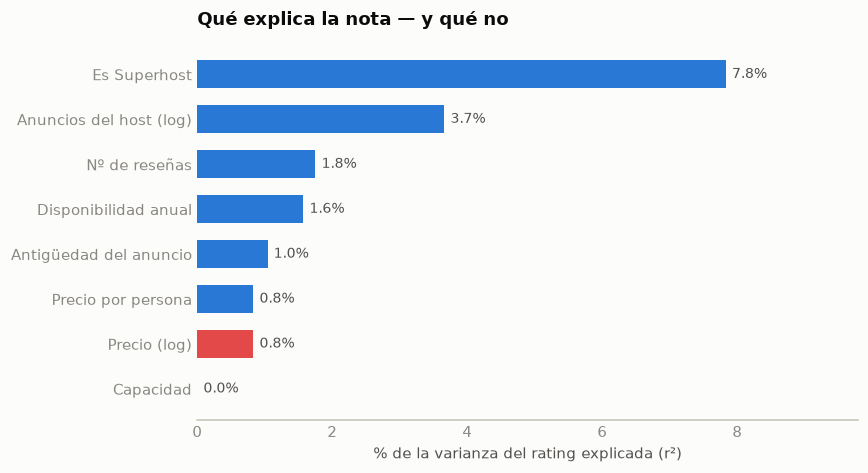

In [6]:
orden = ranking.sort_values('r2_%')
colores = [RED if f == 'Precio (log)' else BLUE for f in orden.index]

fig, ax = plt.subplots(figsize=(8, 4.4))
barras = ax.barh(orden.index, orden['r2_%'], color=colores, height=0.62)
ax.bar_label(barras, fmt='%.1f%%', padding=4, fontsize=9, color=INK2)
ax.set_xlim(0, orden['r2_%'].max() * 1.25)
ax.set_title('Qué explica la nota — y qué no')
ax.set_xlabel('% de la varianza del rating explicada (r²)')
estilo(ax, eje='x')
plt.tight_layout()
plt.show()

**Hallazgo:** el precio (en rojo) queda casi al final. Los dos factores que dominan son de
**anfitrión**, no de alojamiento:

- **Ser Superhost** explica ~8% — casi diez veces más que el precio.
- **Nº de anuncios del host** explica ~4%, y con signo **negativo**.

Lo de Superhost es esperable (el distintivo se concede, en parte, por tener buenas notas: hay
circularidad). Lo del **número de anuncios no lo es en absoluto**: dice que cuantos más pisos
gestiona un anfitrión, **peor** lo valoran. Va contra la intuición de que un operador
profesional ofrece un servicio más pulido. Tiramos de ese hilo.

## 4. El gradiente: a más anuncios por host, peor nota

Agrupamos a los anfitriones por escala, de particular a gran gestor.

In [7]:
ORDEN = ['1 anuncio', '2-5', '6-20', '21+']
b['tipo_host'] = pd.cut(b.calculated_host_listings_count, [0, 1, 5, 20, 10_000], labels=ORDEN)

por_host = b.groupby('tipo_host', observed=True).agg(
    anuncios=('id', 'size'),
    rating=('review_scores_rating', 'mean'),
    calidad_precio=('review_scores_value', 'mean'),
).reindex(ORDEN).round(2)
por_host

,anuncios,rating,calidad_precio
tipo_host,,,
1 anuncio,3756,4.74,4.64
2-5,4178,4.70,4.59
6-20,3613,4.62,4.51
21+,4813,4.52,4.39


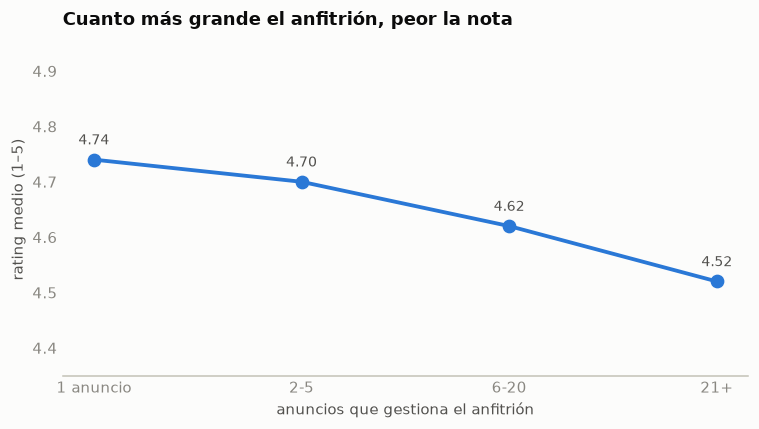

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(por_host.index, por_host.rating, marker='o', color=BLUE, lw=2.5, ms=8)
for x, y in zip(por_host.index, por_host.rating):
    ax.annotate(f'{y:.2f}', (x, y), textcoords='offset points', xytext=(0, 10),
                ha='center', fontsize=9, color=INK2)
ax.set_ylim(4.35, 4.95)
ax.set_title('Cuanto más grande el anfitrión, peor la nota')
ax.set_ylabel('rating medio (1–5)')
ax.set_xlabel('anuncios que gestiona el anfitrión')
estilo(ax)
plt.tight_layout()
plt.show()

El descenso es **monótono**: 4,74 → 4,51 del particular al gran gestor. No es un salto
puntual de un grupo raro, es un gradiente limpio a lo largo de toda la escala.

## 5. ¿Es un espejismo? Dos controles

Dos explicaciones alternativas antes de creérnoslo:

1. **Composición**: quizá los profesionales operan en barrios peores o tienen más habitaciones
   privadas (que puntúan distinto). → control por barrio × tipo.
2. **Antigüedad**: los profesionales podrían tener anuncios más nuevos, y un anuncio nuevo
   acumula notas de otra forma. → control adicional por antigüedad.

In [9]:
def residuo(y, X):
    '''Residuo de y tras regresar sobre X (con constante).'''
    X1 = np.column_stack([np.ones(len(X)), X])
    beta, *_ = np.linalg.lstsq(X1, y, rcond=None)
    return y - X1 @ beta

# --- control 1: barrio x tipo ---
r1, p1, n1, k1 = corr_parcial(b, 'log_host', 'review_scores_rating', CELDAS)

# --- control 2: barrio x tipo + antigüedad del anuncio ---
f = b[['log_host', 'review_scores_rating', 'antiguedad'] + CELDAS].dropna()
f = f[f.groupby(CELDAS)['log_host'].transform('size') >= 5]
g = f.groupby(CELDAS)
xd = (f.log_host - g.log_host.transform('mean')).values
yd = (f.review_scores_rating - g.review_scores_rating.transform('mean')).values
ad = (f.antiguedad - g.antiguedad.transform('mean')).values.reshape(-1, 1)
r2_ = np.corrcoef(residuo(xd, ad), residuo(yd, ad))[0, 1]

r_bruto_host = np.corrcoef(b.log_host, b.review_scores_rating)[0, 1]
print(f'bruto                              r = {r_bruto_host:+.3f}')
print(f'+ control barrio x tipo            r = {r1:+.3f}   p = {p1:.2g}  (n = {n1:,})')
print(f'+ control barrio x tipo y antigüedad r = {r2_:+.3f}   (n = {len(f):,})')

bruto                              r = -0.191
+ control barrio x tipo            r = -0.189   p = 2.4e-128  (n = 16,245)
+ control barrio x tipo y antigüedad r = -0.173   (n = 16,245)


**Hallazgo:** el efecto **apenas se mueve con los controles**: −0,191 en bruto, −0,189
comparando dentro del mismo barrio y tipo, −0,173 añadiendo además la antigüedad. No es
composición (no es que los profesionales operen en barrios peores o con más habitaciones
privadas) ni un artefacto de anuncios más nuevos. Es una de las señales más fuertes de todo el
dataset: explica ~4 veces más varianza que el precio.

Queda la pregunta buena: si el piso profesional no es peor de sitio ni más nuevo, **¿por qué
lo valoran peor?**

## 6. ¿Dónde falla exactamente? Descomposición por aspecto

El rating global es una media de seis subnotas. Si las miramos por separado, deberíamos poder
ver **qué parte de la experiencia** se rompe al escalar.

In [10]:
ASPECTOS = {
    'review_scores_communication': 'Comunicación',
    'review_scores_checkin': 'Check-in',
    'review_scores_accuracy': 'Precisión del anuncio',
    'review_scores_cleanliness': 'Limpieza',
    'review_scores_value': 'Calidad-precio',
    'review_scores_location': 'Ubicación',
}

sub = (b.groupby('tipo_host', observed=True)[list(ASPECTOS)].mean()
       .reindex(ORDEN).rename(columns=ASPECTOS))
sub.loc['CAÍDA (1 → 21+)'] = sub.loc['1 anuncio'] - sub.loc['21+']
sub.round(3)

,Comunicación,Check-in,Precisión del anuncio,Limpieza,Calidad-precio,Ubicación
tipo_host,,,,,,
1 anuncio,4.844,4.812,4.772,4.745,4.641,4.768
2-5,4.802,4.788,4.730,4.726,4.592,4.753
6-20,4.732,4.741,4.681,4.684,4.512,4.741
21+,4.597,4.626,4.595,4.594,4.391,4.697
CAÍDA (1 → 21+),0.247,0.186,0.178,0.151,0.250,0.071


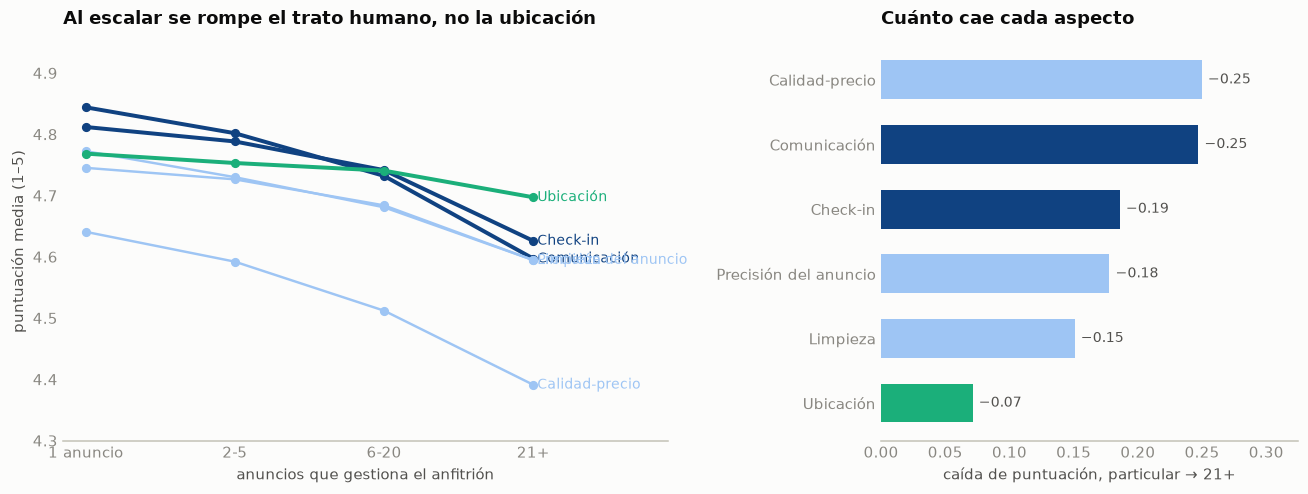

In [11]:
caidas = (sub.loc['1 anuncio'] - sub.loc['21+']).sort_values(ascending=False)
destaca = {'Comunicación': BLUE_D, 'Check-in': BLUE_D, 'Ubicación': AQUA}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), width_ratios=[1.45, 1])

# --- izquierda: slope chart de cada aspecto ---
ax = axes[0]
for aspecto in sub.columns:
    color = destaca.get(aspecto, BLUE_L)
    grosor = 2.6 if aspecto in destaca else 1.6
    ax.plot(ORDEN, sub.loc[ORDEN, aspecto], marker='o', ms=5, lw=grosor, color=color)
    ax.annotate(f' {aspecto}', (3, sub.loc['21+', aspecto]), fontsize=9,
                color=color, va='center')
ax.set_xlim(-0.15, 3.9)
ax.set_ylim(4.3, 4.95)
ax.set_title('Al escalar se rompe el trato humano, no la ubicación')
ax.set_ylabel('puntuación media (1–5)')
ax.set_xlabel('anuncios que gestiona el anfitrión')
estilo(ax)

# --- derecha: magnitud de la caída ---
ax = axes[1]
colores = [destaca.get(a, BLUE_L) for a in caidas.index]
barras = ax.barh(caidas.index[::-1], caidas.values[::-1], color=colores[::-1], height=0.6)
ax.bar_label(barras, fmt='−%.2f', padding=4, fontsize=9, color=INK2)
ax.set_xlim(0, caidas.max() * 1.3)
ax.set_title('Cuánto cae cada aspecto')
ax.set_xlabel('caída de puntuación, particular → 21+')
estilo(ax, eje='x')

plt.tight_layout()
plt.show()

**Este es el hallazgo del notebook.** La caída no está repartida: se concentra donde interviene
una **persona**.

- Lo que más se hunde es **comunicación** (−0,25) y la valoración de **calidad-precio**
  (−0,25), seguidas de **check-in** (−0,19) y **precisión del anuncio** (−0,18): justo lo que
  un operador con 200 pisos automatiza o delega (mensajes plantilla, cajas de llaves, sin
  anfitrión, fotos y descripciones estandarizadas).
- **Limpieza** cae menos (−0,15) pese a ser lo más fácil de externalizar: los profesionales sí
  mantienen el estándar operativo.
- **Ubicación** (−0,07) —lo único que el anfitrión **no puede cambiar**— es lo que menos se
  mueve, y funciona como *control interno*: si la caída fuera un sesgo general de los huéspedes
  contra los profesionales, la ubicación caería igual que el resto. No lo hace.

Dicho de otro modo: **lo que se pierde al escalar no es el piso, es el trato**.

## 7. ¿Lo compensan bajando el precio?

Si el producto es peor, cabría esperar un descuento. O al revés: que el profesional cobre una
prima por su escala y su marca. Miramos el **precio por persona**, que permite comparar un
estudio con un piso de seis plazas.

Un matiz metodológico importante: para esta pregunta **no** exigimos que el anuncio tenga nota.
El precio existe con o sin reseñas, y filtrar por nota dejaría fuera a los anuncios
profesionales aún sin reseñar, sesgando la comparación. Usamos por tanto toda la base con
precio conocido.

base con precio (sin exigir nota): 18,980 anuncios



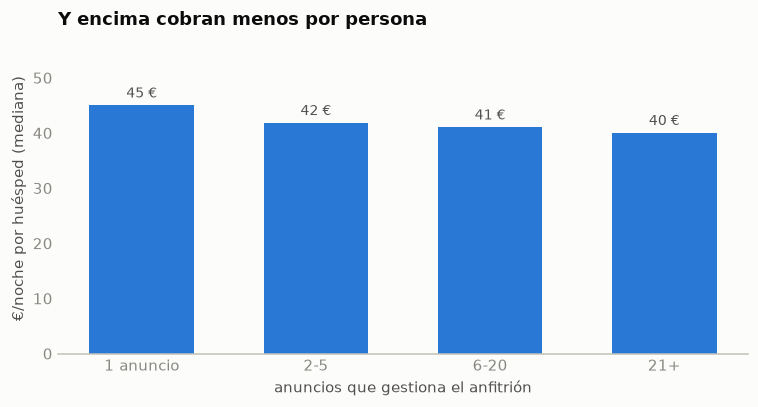

anuncios del host ~ precio por persona (dentro de barrio x tipo): r = -0.114  p = 1.3e-54  n = 18,868


In [12]:
bp = full[full.price.notna() & (full.price < full.price.quantile(0.99))].copy()
bp['price_pp'] = bp['price'] / bp['accommodates'].clip(lower=1)
bp['log_host'] = np.log(bp['calculated_host_listings_count'].clip(lower=1))
bp['tipo_host'] = pd.cut(bp.calculated_host_listings_count, [0, 1, 5, 20, 10_000], labels=ORDEN)

pp = bp.groupby('tipo_host', observed=True).price_pp.median().reindex(ORDEN)
print(f'base con precio (sin exigir nota): {len(bp):,} anuncios\n')

fig, ax = plt.subplots(figsize=(7, 3.8))
barras = ax.bar(pp.index, pp.values, color=BLUE, width=0.6)
ax.bar_label(barras, fmt='%.0f €', padding=3, fontsize=9, color=INK2)
ax.set_ylim(0, pp.max() * 1.25)
ax.set_title('Y encima cobran menos por persona')
ax.set_ylabel('€/noche por huésped (mediana)')
ax.set_xlabel('anuncios que gestiona el anfitrión')
estilo(ax)
plt.tight_layout()
plt.show()

r_pp, p_pp, n_pp, _ = corr_parcial(bp, 'log_host', 'price_pp', CELDAS)
print(f'anuncios del host ~ precio por persona (dentro de barrio x tipo): '
      f'r = {r_pp:+.3f}  p = {p_pp:.2g}  n = {n_pp:,}')

**Hallazgo:** no hay prima por escala. El precio por plaza baja de forma **monótona** con el
tamaño del anfitrión (45 € → 40 €), y la relación se mantiene al comparar dentro del mismo
barrio y tipo (r = −0,11), así que tampoco es un efecto de dónde o qué alquilan.

Peor producto *y* más barato: el negocio del profesional es el **volumen**, no la calidad. Es
el detalle que descarta la explicación más benigna —«cobran más porque dan un servicio
premium»—: ni cobran más, ni puntúan mejor.

## 8. Conclusiones y límites

**Lo que encontramos**, empezando por un resultado que parecía un callejón sin salida:

1. El precio explica **0,8%** de la nota. El efecto es real (sobrevive al control por barrio y
   tipo: r pasa de +0,091 a +0,096) pero **irrelevante en magnitud**. La lectura fácil «se paga
   la calidad» no se sostiene.
2. Lo que sí predice la nota es **quién gestiona** el alojamiento. El nº de anuncios del host
   explica ~4 veces más varianza que el precio (3,7% frente a 0,8%), y **con signo negativo**.
3. El efecto **resiste los controles**: r = −0,191 en bruto, −0,189 dentro de barrio × tipo,
   −0,173 añadiendo antigüedad.
4. La caída se concentra en **comunicación** (−0,25), **calidad-precio** (−0,25) y **check-in**
   (−0,19), mientras la **ubicación** apenas se mueve (−0,07): se degrada el trato humano, no
   el inmueble.
5. Los profesionales **no cobran prima**: 45 € → 40 € por plaza, también dentro del mismo
   barrio y tipo (r = −0,11).

**Límites, explícitos:**

- Es **correlación, no causalidad**. No demostramos que profesionalizarse empeore un
  alojamiento; es igual de compatible con que perfiles distintos de anfitrión acaben en
  escalas distintas (selección). Haría falta seguir a los mismos anuncios en el tiempo, o al
  mismo host al crecer, para hablar de causa.
- Sesgo de selección en quién reseña: sólo vemos a huéspedes que se alojaron y escribieron.
- El 15,5% de anuncios sin precio queda fuera del análisis; como vimos en el notebook 01, son
  sobre todo anuncios **inactivos**, así que este notebook describe el mercado *activo*.
- «Superhost» es parcialmente circular (se concede por buenas notas): lo usamos como referencia
  de magnitud, no como hallazgo causal.

**Implicación para el dashboard:** este hallazgo merece **pestaña propia** («Hosts
profesionales»), con el *slope chart* de aspectos como gráfico principal —es el que muestra el
mecanismo, no sólo el efecto— acompañado del precio por persona. Y obliga a **corregir** la
pestaña de precio: el texto que sugería que «pagar más compra mejor experiencia» exagera un
efecto del 1%, y debe sustituirse por el ranking de tamaños de efecto de la sección 3.